# Initial-value problems and one-step convergence

**Source mapping:** Vercauteren, Simulation and Modelling 2 (9 July 2025), §4.1–4.3, pp. 22–26.

Independent study companion; explanations and experiments are newly written. Read in the README order.

## Model and reasoning

For $y'=f(t,y)$, integrating one time interval gives $y(t+h)=y(t)+\int_t^{t+h}f(s,y(s))ds$. Different quadrature approximations produce Euler, Heun and Runge–Kutta methods. Continuity in t and local Lipschitz continuity in y provide local existence and uniqueness; finite-time blow-up still requires attention for nonlinear problems.

Euler uses the initial slope. Heun averages initial and predicted final slopes. RK4 combines four stages. The one-step defect for an order-p method is O(h^(p+1)); the notes divide this defect by h when defining truncation error. Under stability and regularity assumptions, accumulation over a fixed interval gives global error O(h^p). Do not confuse consistency with absolute stability over long times.

## Reproducible experiment

Predict the plot before running. All parameters below are illustrative, not measured environmental data.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (8, 4), "axes.grid": True})
rng = np.random.default_rng(42)

Euler observed order: 1.0075973087455237
Heun observed order: 2.0135938502353654
RK4 observed order: 4.015039812839075


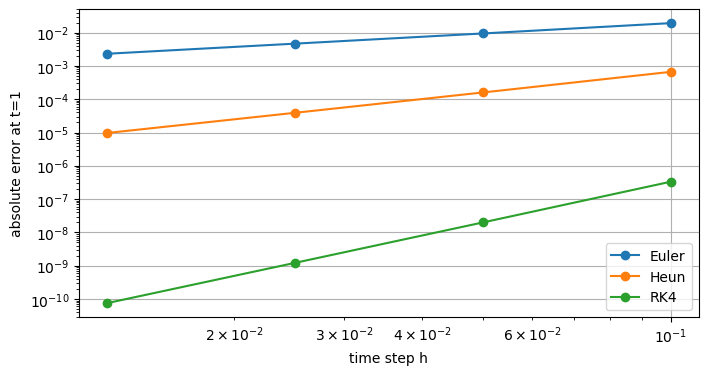

In [2]:
def step(y,h,method):
 f=lambda y:-y
 k1=f(y)
 if method=="Euler": return y+h*k1
 if method=="Heun": return y+h*(k1+f(y+h*k1))/2
 k2=f(y+h*k1/2);k3=f(y+h*k2/2);k4=f(y+h*k3)
 return y+h*(k1+2*k2+2*k3+k4)/6
ns=np.array([10,20,40,80]);hs=1/ns
for method,p in [("Euler",1),("Heun",2),("RK4",4)]:
 errors=[]
 for n in ns:
  y=1.
  for _ in range(n): y=step(y,1/n,method)
  errors.append(abs(y-np.exp(-1)))
 order=np.log(errors[-2]/errors[-1])/np.log(2)
 print(method,"observed order:",order);assert abs(order-p)<.15
 plt.loglog(hs,errors,"o-",label=method)
plt.xlabel("time step h");plt.ylabel("absolute error at t=1");plt.legend();plt.show()

## Read the result

The log–log slope measures convergence in this smooth test problem. Eventually roundoff can obscure high-order convergence. A single small error does not establish an order.

## Your turn

Derive the Euler local defect using a Taylor expansion. Add a perturbed initial value and distinguish problem sensitivity from discretisation error.

Record: prediction → observation → explanation. A successful assertion checks this example; it is not a general proof.